# GRASP: planning by gradient descent

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/planning/grasp.ipynb)

[GRASP](https://arxiv.org/abs/2602.00475) ([code](https://github.com/michael-psenka/grasp)) plans with a world model by gradient descent instead of sampling. The latents along the plan become free variables, so each step is predicted on its own instead of through the whole rollout; noise on those latents helps escape local minima, and a periodic sync with a real rollout keeps the plan feasible.

Here a small [LeWM](https://arxiv.org/abs/2603.19312) learns Two-Rooms from pixels, and GRASP and CEM plan with it toward goals in the other room.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [2]:
import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import TwoRooms
from torch_world.models import LeWM
from torch_world.nn import CLSEncoder
from torch_world.planning import CEM, GRASP
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
SKIP = 5  # as in LeWM, the model sees every 5th frame and the 5 actions in between

## Data and model
A point wanders through two rooms joined by a door. A small LeWM learns from the pixels with next-embedding prediction and SIGReg.

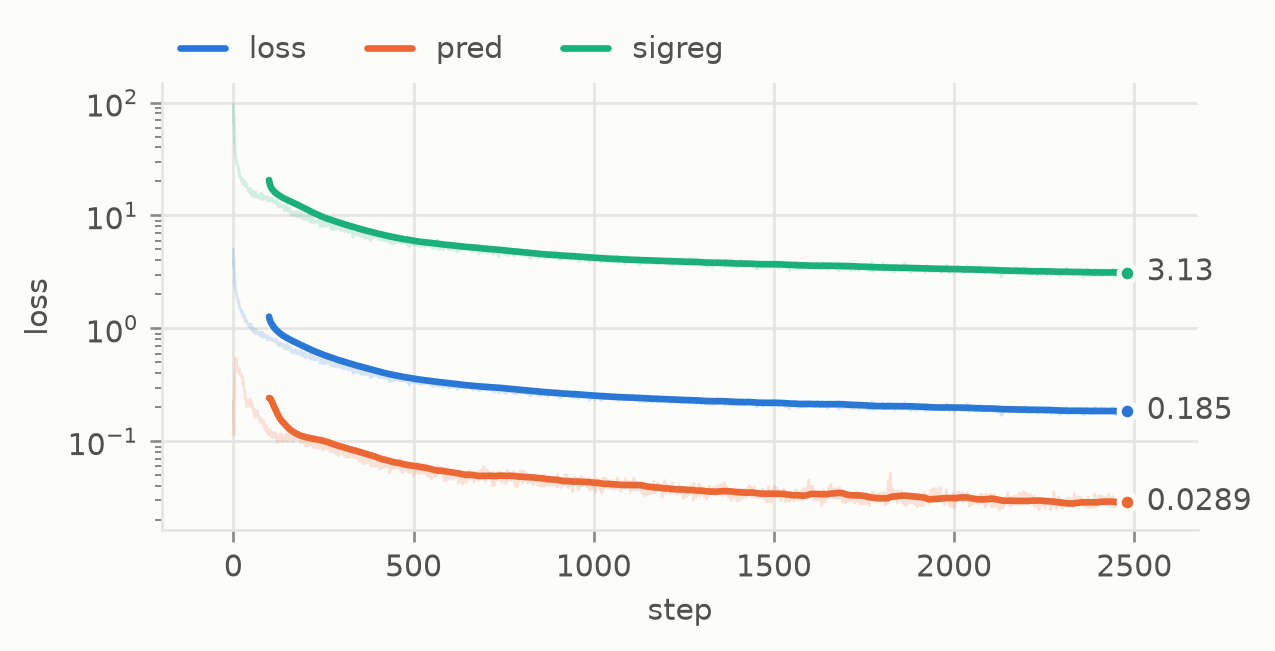

In [3]:
data = TwoRooms(batch_size=1024, device=device).collect(50, generator=torch.Generator().manual_seed(0))
loader = DataLoader(TrajectoryDataset(data, window=4, frameskip=SKIP), batch_size=256, shuffle=True, drop_last=True)

encoder = CLSEncoder(img_size=64, patch_size=8, depth=6, num_heads=6)
model = LeWM(encoder, action_dim=2 * SKIP, depth=6, num_heads=8, head_dim=32, mlp_dim=768, proj_dim=768, lamb=0.05).to(device)
log = fit(model, loader, epochs=20)
plots.curves(log, smooth=100)

## Plan with CEM and GRASP
Both plan 5 chunks of 5 actions on the same model and run the first chunk before planning again. CEM uses LeWM's settings (300 samples, 30 iterations); GRASP those of the authors' LeWM adapter (750 gradient steps, a sync every 50).

In [4]:
env = TwoRooms(batch_size=32, device=device)
start, goal = env.tasks(generator=torch.Generator().manual_seed(1))  # start and goal in opposite rooms
goal_images = env.render(goal)

planners = {
    "CEM": CEM(horizon=5, action_dim=2 * SKIP, num_samples=300, num_elites=30, iterations=30, bounds=(-1, 1)),
    "GRASP": GRASP(horizon=5, action_dim=2 * SKIP, bounds=(-1, 1)),
}
policies = {name: evaluation.goal_policy(model, p, goal_images, action_dim=2, execute=1) for name, p in planners.items()}
policies["random actions"] = evaluation.random_policy(env)
result = evaluation.goal_reaching(env, policies, start, goal, steps=60, success="reached")
result

                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
CEM                62% [45%, 77%]      62%    29.1           0.181     0.558   0.206       0.528   5.88e+03
GRASP              22% [11%, 39%]      22%    12.3           0.574    -0.074  0.0675       0.728   4.13e+03
random actions       3% [1%, 16%]       3%      46           0.545    0.0791 0.00503        1.04     0.0825

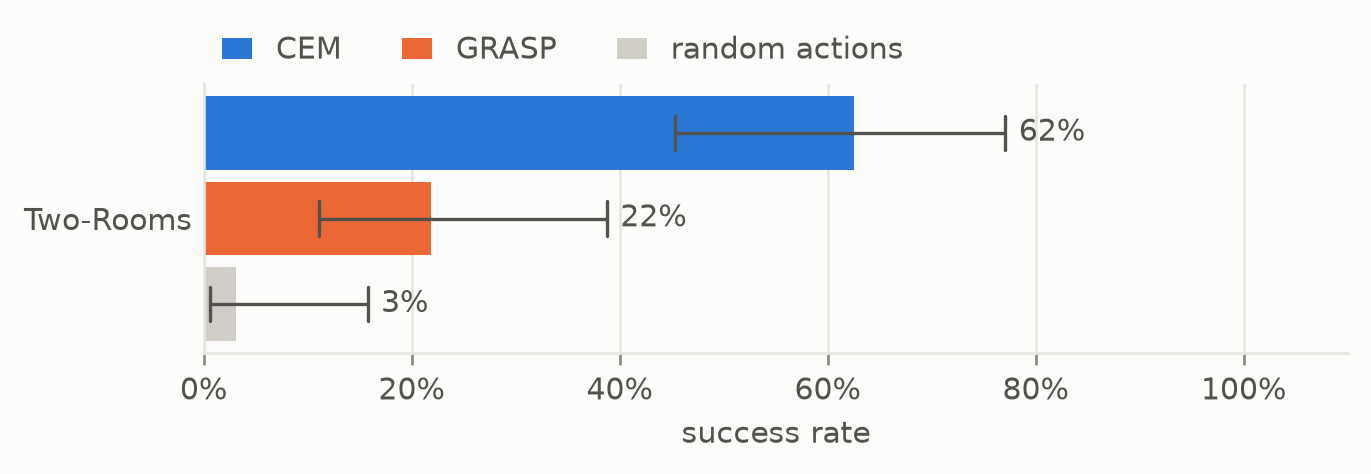

In [5]:
plots.bars({"Two-Rooms": result.intervals()}, xlabel="success rate", baseline="random actions")

The paths of GRASP; the darker, the later:

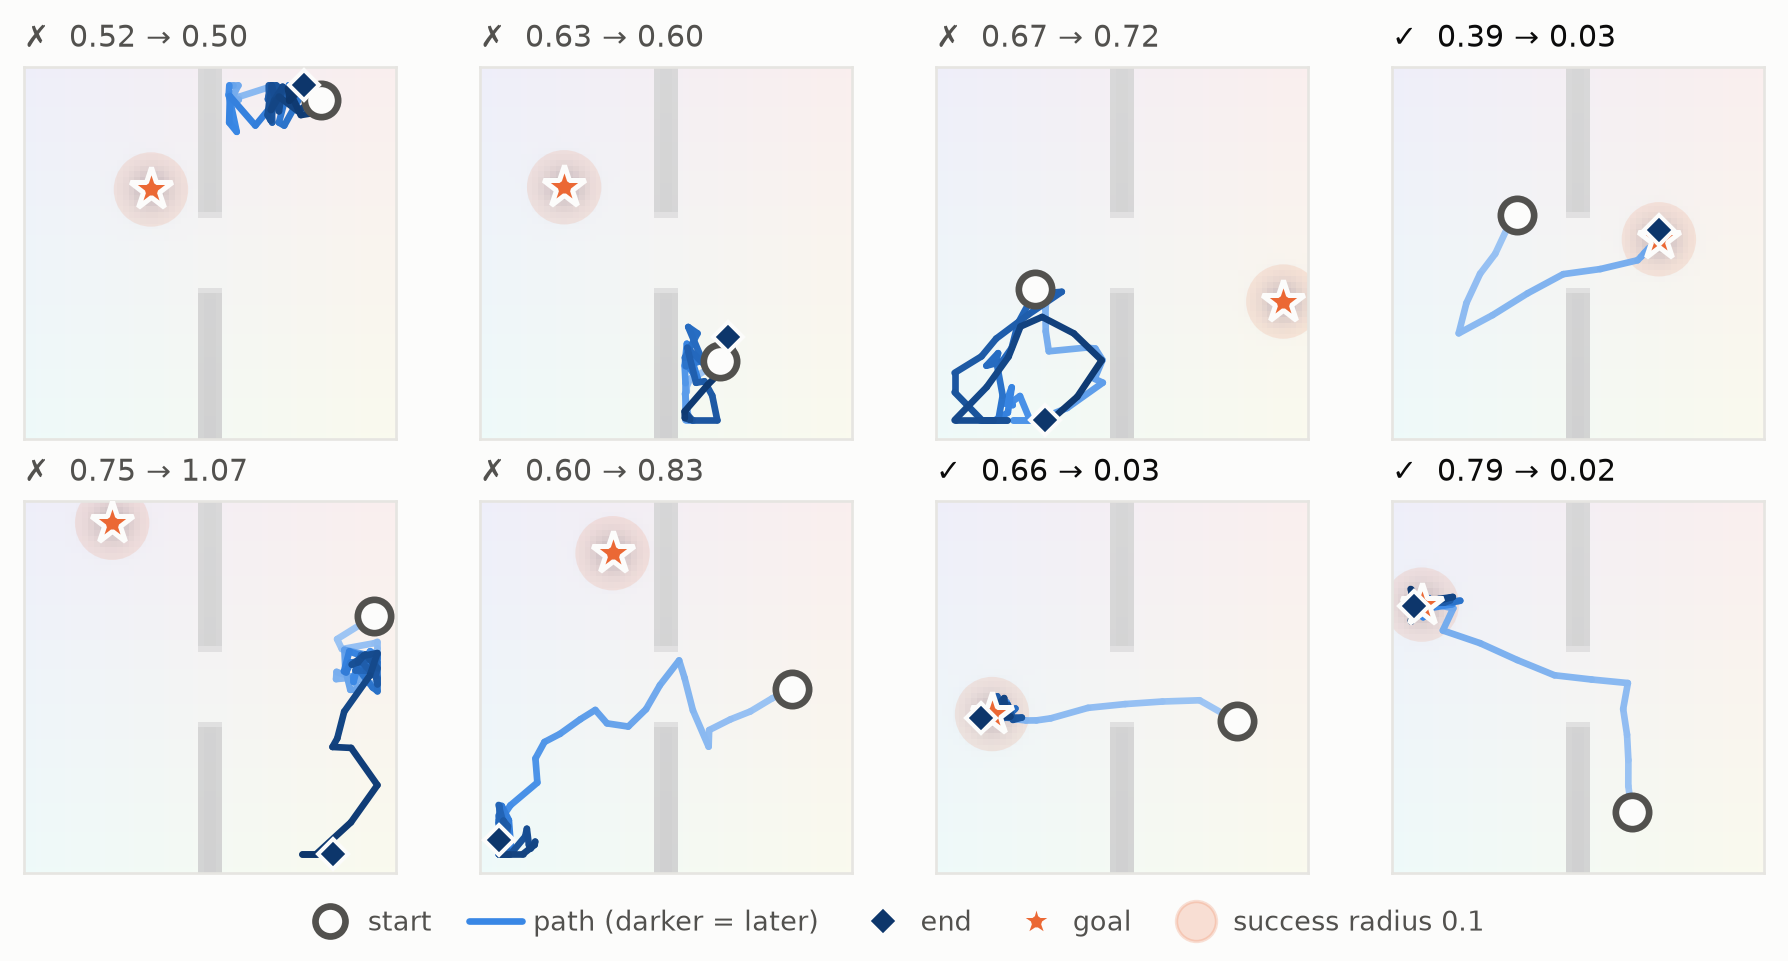

In [6]:
plots.trajectories(result.paths["GRASP"][:8], goal[:8], radius=env.radius, background=goal_images[:8], success=result.success["GRASP"][:8])

## Summary
GRASP is a drop-in alternative to CEM, with the same call `planner(model, z, goal)` on any differentiable `WorldModel`. It refines one plan per task by gradient descent where CEM rolls out hundreds of samples per iteration; the `ms / step` column above compares their cost. Its knobs are `iterations`, the learning rates of latents and actions, the latent `noise`, and how often and how hard the plan is synced with a real rollout (`sync_every`, `sync_steps`, `sync_lr`).